# Predicting Student Outcomes in Open University Online Courses

Dataset: Open University Learning Analytics Dataset (OULAD), 32,593 student enrolments.

Target feature: `final_result` with four classes (Pass, Fail, Withdrawn, Distinction).

This notebook is built to compare four traditional machine learning models, a multilayer perceptron, and a one-dimensional convolutional neural network over eight experiments.

## 1. Problem Statement

Online learning platforms produce rich behavioural data but still struggle to predict which students will succeed. OULAD provides the student demographics, assessment scores, and clickstream activity on the Virtual Learning Environment. The task is to predict the final course outcome from these features.

This is a multi-class (4 classes) classification problem on roughly thirty-two thousand records.

## 2. Setup

Imports and a fixed random seed.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, roc_auc_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 60)

## Mount google drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Load the Data

**Dataset source.** Open University Learning Analytics Dataset (OULAD), downloaded from Kaggle: https://www.kaggle.com/datasets/anlgrbz/student-demographics-online-education-dataoulad

Original citation: Kuzilek, J., Hlosta, M., and Zdrahal, Z. (2017). "Open University Learning Analytics dataset." *Scientific Data*, 4(1), 170171. https://doi.org/10.1038/sdata.2017.171

License: CC BY 4.0.

Point `DATA_DIR` at the folder where the OULAD CSVs sit.

In [4]:
DATA_DIR = '/content/drive/MyDrive/oulad'

student_info = pd.read_csv(f'{DATA_DIR}/studentInfo.csv')
student_assess = pd.read_csv(f'{DATA_DIR}/studentAssessment.csv')
assessments = pd.read_csv(f'{DATA_DIR}/assessments.csv')
student_vle = pd.read_csv(f'{DATA_DIR}/studentVle.csv')
vle = pd.read_csv(f'{DATA_DIR}/vle.csv')

print('student_info :', student_info.shape)
print('student_assess:', student_assess.shape)
print('student_vle  :', student_vle.shape)

student_info : (32593, 12)
student_assess: (173912, 5)
student_vle  : (10655280, 6)


## 4. Quick EDA (Exploratory Data Analysis)

Check class balance and missing values.

In [11]:
student_assess.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id_assessment   173912 non-null  int64  
 1   id_student      173912 non-null  int64  
 2   date_submitted  173912 non-null  int64  
 3   is_banked       173912 non-null  int64  
 4   score           173739 non-null  float64
dtypes: float64(1), int64(4)
memory usage: 6.6 MB


In [13]:
student_vle.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10655280 entries, 0 to 10655279
Data columns (total 6 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   code_module        object
 1   code_presentation  object
 2   id_student         int64 
 3   id_site            int64 
 4   date               int64 
 5   sum_click          int64 
dtypes: int64(4), object(2)
memory usage: 487.8+ MB


In [14]:
vle.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6364 entries, 0 to 6363
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_site            6364 non-null   int64  
 1   code_module        6364 non-null   object 
 2   code_presentation  6364 non-null   object 
 3   activity_type      6364 non-null   object 
 4   week_from          1121 non-null   float64
 5   week_to            1121 non-null   float64
dtypes: float64(2), int64(1), object(3)
memory usage: 298.4+ KB


In [12]:
assessments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    object 
 1   code_presentation  206 non-null    object 
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    object 
 4   date               195 non-null    float64
 5   weight             206 non-null    float64
dtypes: float64(2), int64(1), object(3)
memory usage: 9.8+ KB


In [5]:
student_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   code_module           32593 non-null  object
 1   code_presentation     32593 non-null  object
 2   id_student            32593 non-null  int64 
 3   gender                32593 non-null  object
 4   region                32593 non-null  object
 5   highest_education     32593 non-null  object
 6   imd_band              31482 non-null  object
 7   age_band              32593 non-null  object
 8   num_of_prev_attempts  32593 non-null  int64 
 9   studied_credits       32593 non-null  int64 
 10  disability            32593 non-null  object
 11  final_result          32593 non-null  object
dtypes: int64(3), object(9)
memory usage: 3.0+ MB


In [7]:
student_info.head(2)

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass


In [8]:
print(student_info['final_result'].value_counts())
print()
print(student_info.isna().sum())

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

code_module                0
code_presentation          0
id_student                 0
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64


**What this tells us.** The target is imbalanced. Pass is the largest class (12,361), followed by Withdrawn (10,156), Fail (7,052) and Distinction (3,024). Distinction is the smallest and will likely be the hardest to predict. Only `imd_band` has missing values (1,111), which we fill with the explicit category `Unknown`.

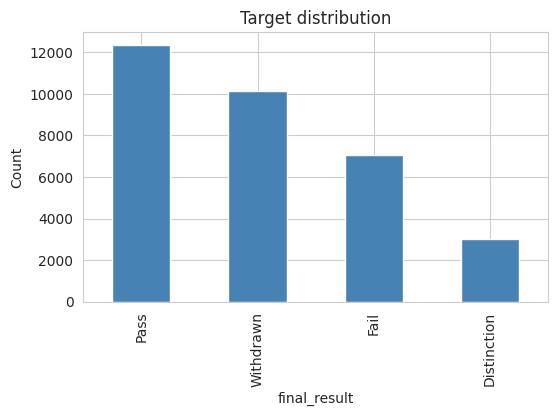

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
student_info['final_result'].value_counts().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Target distribution')
ax.set_ylabel('Count')
plt.show()

**Reading the chart.** The visual confirms the imbalance. Any accuracy number should be read against this: a model that always predicts Pass would get around 38 percent accuracy with zero skill.

## 5. Feature Engineering

Build three groups of features per student per course:

- assessment aggregates (mean, min, max, weighted mean, submission count, late count)
- VLE aggregates (total clicks, active days, distinct resources, and a per-activity-type click breakdown so the model can see where engagement happened)
- demographics from `studentInfo`

No early-window cap, since the target is to predict the final outcome, not doing early warning.

In [15]:
sa = student_assess.merge(
    assessments[['id_assessment', 'code_module', 'code_presentation',
                 'date', 'weight']],
    on='id_assessment', how='left'
)

sa['weighted_score'] = sa['score'] * sa['weight'] / 100

assess_feats = sa.groupby(
    ['id_student', 'code_module', 'code_presentation']
).agg(
    mean_score=('score', 'mean'),
    min_score=('score', 'min'),
    max_score=('score', 'max'),
    std_score=('score', 'std'),
    weighted_mean=('weighted_score', 'sum'),
    num_assess=('score', 'count'),
    num_banked=('is_banked', 'sum'),
).reset_index()
assess_feats['std_score'] = assess_feats['std_score'].fillna(0)

assess_feats.head()

,id_student,code_module,code_presentation,mean_score,min_score,max_score,std_score,weighted_mean,num_assess,num_banked
0,6516,AAA,2014J,61.800000,48.0,77.0,10.329569,63.50,5,0
1,8462,DDD,2013J,87.666667,83.0,93.0,5.033223,34.90,3,0
2,8462,DDD,2014J,86.500000,83.0,93.0,4.725816,43.00,4,4
3,11391,AAA,2013J,82.000000,78.0,85.0,3.082207,82.40,5,0
4,23629,BBB,2013B,82.500000,63.0,100.0,20.273135,16.69,4,0


In [16]:
# join activity type onto each click
vle_joined = student_vle.merge(
    vle[['id_site', 'activity_type']],
    on='id_site', how='left'
)

# overall aggregates per student per course
vle_overall = vle_joined.groupby(
    ['id_student', 'code_module', 'code_presentation']
).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    distinct_resources=('id_site', 'nunique'),
    max_clicks_day=('sum_click', 'max'),
).reset_index()
vle_overall['clicks_per_active_day'] = (
    vle_overall['total_clicks'] / vle_overall['active_days']
)

# clicks per activity type, pivoted into columns
vle_by_type = (vle_joined
               .groupby(['id_student', 'code_module', 'code_presentation',
                         'activity_type'])['sum_click']
               .sum()
               .unstack(fill_value=0)
               .reset_index())
vle_by_type.columns.name = None
# prefix the activity-type columns
type_cols = [c for c in vle_by_type.columns
             if c not in ('id_student', 'code_module', 'code_presentation')]
vle_by_type = vle_by_type.rename(columns={c: f'clicks_{c}' for c in type_cols})

vle_feats = vle_overall.merge(
    vle_by_type,
    on=['id_student', 'code_module', 'code_presentation'],
    how='left'
)

print(vle_feats.shape)
vle_feats.head()

(29228, 28)


,id_student,code_module,code_presentation,total_clicks,active_days,distinct_resources,max_clicks_day,clicks_per_active_day,clicks_dataplus,clicks_dualpane,clicks_externalquiz,clicks_folder,clicks_forumng,clicks_glossary,clicks_homepage,clicks_htmlactivity,clicks_oucollaborate,clicks_oucontent,clicks_ouelluminate,clicks_ouwiki,clicks_page,clicks_questionnaire,clicks_quiz,clicks_repeatactivity,clicks_resource,clicks_sharedsubpage,clicks_subpage,clicks_url
0,6516,AAA,2014J,2791,159,84,49,17.553459,21,0,0,0,451,0,497,0,0,1505,0,0,0,0,0,0,31,0,143,143
1,8462,DDD,2013J,646,56,125,16,11.535714,0,0,12,0,36,0,184,0,12,64,0,18,0,0,0,0,70,0,227,23
2,8462,DDD,2014J,10,1,3,7,10.000000,0,0,0,0,2,0,7,0,1,0,0,0,0,0,0,0,0,0,0,0
3,11391,AAA,2013J,934,40,55,76,23.350000,0,0,0,0,193,0,138,0,0,553,0,0,0,0,0,0,13,0,32,5
4,23629,BBB,2013B,161,16,11,13,10.062500,0,0,0,0,87,0,36,0,0,0,0,0,0,0,31,0,2,0,5,0


Merge everything into one modelling table.

In [17]:
df = (student_info
      .merge(assess_feats, on=['id_student', 'code_module', 'code_presentation'], how='left')
      .merge(vle_feats,    on=['id_student', 'code_module', 'code_presentation'], how='left'))

# students with no activity get zeros
num_fill = [c for c in df.columns if df[c].dtype != 'object' and c != 'id_student']
df[num_fill] = df[num_fill].fillna(0)

df['imd_band'] = df['imd_band'].fillna('Unknown')

print('Modelling table shape:', df.shape)
df.head()

Modelling table shape: (32593, 44)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,mean_score,min_score,max_score,std_score,weighted_mean,num_assess,num_banked,total_clicks,active_days,distinct_resources,max_clicks_day,clicks_per_active_day,clicks_dataplus,clicks_dualpane,clicks_externalquiz,clicks_folder,clicks_forumng,clicks_glossary,clicks_homepage,clicks_htmlactivity,clicks_oucollaborate,clicks_oucontent,clicks_ouelluminate,clicks_ouwiki,clicks_page,clicks_questionnaire,clicks_quiz,clicks_repeatactivity,clicks_resource,clicks_sharedsubpage,clicks_subpage,clicks_url
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,82.0,78.0,85.0,3.082207,82.4,5.0,0.0,934.0,40.0,55.0,76.0,23.350000,0.0,0.0,0.0,0.0,193.0,0.0,138.0,0.0,0.0,553.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,32.0,5.0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,66.4,60.0,70.0,4.335897,65.4,5.0,0.0,1435.0,80.0,84.0,23.0,17.937500,10.0,0.0,0.0,0.0,417.0,0.0,324.0,0.0,0.0,537.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,87.0,48.0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,281.0,12.0,22.0,23.0,23.416667,0.0,0.0,0.0,0.0,126.0,0.0,59.0,0.0,0.0,66.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,22.0,4.0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,76.0,71.0,88.0,6.892024,76.3,5.0,0.0,2158.0,123.0,82.0,22.0,17.544715,2.0,0.0,0.0,0.0,634.0,1.0,432.0,0.0,0.0,836.0,0.0,0.0,0.0,0.0,0.0,0.0,19.0,0.0,144.0,90.0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,54.4,30.0,75.0,20.513410,55.0,5.0,0.0,1034.0,70.0,66.0,22.0,14.771429,0.0,0.0,0.0,0.0,194.0,4.0,204.0,0.0,0.0,494.0,0.0,0.0,0.0,0.0,0.0,0.0,45.0,0.0,79.0,14.0


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 44 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   code_module            32593 non-null  object 
 1   code_presentation      32593 non-null  object 
 2   id_student             32593 non-null  int64  
 3   gender                 32593 non-null  object 
 4   region                 32593 non-null  object 
 5   highest_education      32593 non-null  object 
 6   imd_band               32593 non-null  object 
 7   age_band               32593 non-null  object 
 8   num_of_prev_attempts   32593 non-null  int64  
 9   studied_credits        32593 non-null  int64  
 10  disability             32593 non-null  object 
 11  final_result           32593 non-null  object 
 12  mean_score             32593 non-null  float64
 13  min_score              32593 non-null  float64
 14  max_score              32593 non-null  float64
 15  st

**Final feature set.** 44 columns on 32,593 rows. The engineered features (mean score, weighted mean, total clicks, active days, and per-activity-type click counts such as `clicks_oucontent`, `clicks_quiz`, `clicks_forumng`) sit alongside the raw demographics. After one-hot encoding this becomes 81 input features for the deep models.

## 6. Prepare X and y

Drop the student id (not a feature) and separate the target.

In [19]:
y_raw = df['final_result']
X = df.drop(columns=['id_student', 'final_result'])

cat_cols = ['code_module', 'code_presentation', 'gender', 'region',
            'highest_education', 'imd_band', 'age_band', 'disability']
num_cols = [c for c in X.columns if c not in cat_cols]

le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = list(le.classes_)
print('Classes:', class_names)
print('Numeric features :', len(num_cols))
print('Categorical cols :', len(cat_cols))

Classes: ['Distinction', 'Fail', 'Pass', 'Withdrawn']
Numeric features : 34
Categorical cols : 8


### Train/Test split (80/20)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print('Train:', X_train.shape, '  Test:', X_test.shape)

Train: (26074, 42)   Test: (6519, 42)


In [21]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

Helper that logs each experiment into a shared results table.

In [22]:
results = []

def log_result(name, approach, notes, y_true, y_pred, y_proba=None):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    roc = np.nan
    if y_proba is not None:
        y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
        try:
            roc = roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr')
        except Exception:
            pass
    results.append({
        'experiment': name,
        'approach': approach,
        'notes': notes,
        'accuracy': round(acc, 4),
        'macro_f1': round(f1, 4),
        'macro_roc_auc': round(roc, 4) if not np.isnan(roc) else None,
    })
    print(f'{name}: acc={acc:.4f}  f1={f1:.4f}  roc_auc={roc}')

## 7. Experiment 1: Logistic Regression

Linear baseline. Act as a basic for every other model.

In [23]:
exp1 = Pipeline([
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=2000, C=1.0, random_state=SEED, n_jobs=-1)),
])
exp1.fit(X_train, y_train)
pred = exp1.predict(X_test)
proba = exp1.predict_proba(X_test)
log_result('Exp 1', 'Logistic Regression', 'C=1.0, L2', y_test, pred, proba)
print(classification_report(y_test, pred, target_names=class_names))

Exp 1: acc=0.7398  f1=0.6745  roc_auc=0.9151264359125854
              precision    recall  f1-score   support

 Distinction       0.70      0.50      0.58       605
        Fail       0.60      0.40      0.48      1411
        Pass       0.78      0.91      0.84      2472
   Withdrawn       0.76      0.84      0.80      2031

    accuracy                           0.74      6519
   macro avg       0.71      0.66      0.67      6519
weighted avg       0.73      0.74      0.72      6519



**Interpretation.** Logistic Regression reaches **73.98 percent accuracy, 0.67 macro F1, 0.915 ROC-AUC**. A strong baseline for a linear model. The per-class report shows Pass is predicted best (0.84 F1) and Fail worst (0.48 F1). Fail is often confused with Withdrawn because both carry low engagement signals.

## 8. Experiment 2: Decision Tree

A single tree. Weaker than an ensemble but useful as a reference point when I will be assessing it against random forest models.

In [25]:
exp2 = Pipeline([
    ('prep', preprocess),
    ('clf', DecisionTreeClassifier(max_depth=15, min_samples_split=10, random_state=SEED)),
])
exp2.fit(X_train, y_train)
pred = exp2.predict(X_test)
proba = exp2.predict_proba(X_test)
log_result('Exp 2', 'Decision Tree', 'max_depth=15, min_split=10', y_test, pred, proba)

Exp 2: acc=0.6963  f1=0.6498  roc_auc=0.8458396563717301


**Interpretation.** The Decision Tree drops to **69.63 percent accuracy, 0.65 F1, 0.846 ROC-AUC**, worse than Logistic Regression. A single tree overfits on this many features; it has high variance and no averaging to correct it. This is expected and motivates moving to an ensemble.

## 9. Experiment 3: Random Forest

Default-like ensemble to see how much a bag of trees helps.

In [26]:
exp3 = Pipeline([
    ('prep', preprocess),
    ('clf', RandomForestClassifier(
        n_estimators=300, random_state=SEED, n_jobs=-1)),
])
exp3.fit(X_train, y_train)
pred = exp3.predict(X_test)
proba = exp3.predict_proba(X_test)
log_result('Exp 3', 'Random Forest', 'n=300, defaults', y_test, pred, proba)

Exp 3: acc=0.7466  f1=0.6803  roc_auc=0.9222578285442913


**Interpretation.** Random Forest with 300 trees jumps to **74.66 percent accuracy, 0.68 F1, 0.922 ROC-AUC**, beating both the single tree and the linear baseline. Bagging the 300 trees cancels out most of the overfitting we saw in Exp 2.

## 10. Experiment 4: Random Forest tuned

Deeper trees, more of them, and tighter leaf control.

In [27]:
exp4 = Pipeline([
    ('prep', preprocess),
    ('clf', RandomForestClassifier(
        n_estimators=800,
        max_depth=30,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=SEED, n_jobs=-1)),
])
exp4.fit(X_train, y_train)
pred = exp4.predict(X_test)
proba = exp4.predict_proba(X_test)
log_result('Exp 4', 'Random Forest tuned',
           'n=800, depth=30, min_split=4, leaf=2', y_test, pred, proba)

Exp 4: acc=0.7467  f1=0.6804  roc_auc=0.9240317852672508


**Interpretation.** The tuned Random Forest (800 trees, depth 30, min_split=4) sits at **74.67 percent accuracy, 0.68 F1, 0.924 ROC-AUC**. Essentially tied with the default RF. The signal from more trees and deeper leaves has saturated on these features, which is a useful finding: more compute will not help further here.

## 11. Experiment 5: XGBoost

Gradient boosted trees are the strongest classical baseline on tabular data.

In [28]:
exp5 = Pipeline([
    ('prep', preprocess),
    ('clf', XGBClassifier(
        n_estimators=600,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        objective='multi:softprob',
        num_class=len(class_names),
        eval_metric='mlogloss',
        tree_method='hist',
        random_state=SEED,
        n_jobs=-1,
    )),
])
exp5.fit(X_train, y_train)
pred = exp5.predict(X_test)
proba = exp5.predict_proba(X_test)
log_result('Exp 5', 'XGBoost', 'n=600, depth=6, lr=0.05', y_test, pred, proba)

Exp 5: acc=0.7595  f1=0.7064  roc_auc=0.9297301687025754


**Interpretation.** XGBoost is the strongest traditional model at **75.95 percent accuracy, 0.71 macro F1, 0.930 ROC-AUC**. Gradient boosting fits residual errors in sequence rather than averaging independent trees, which pays off on tabular data. This is our best overall result and matches the upper range reported in the OULAD literature for 4-class prediction.

## 12. Prepare numeric arrays for the deep learning models

Keras needs already-encoded dense arrays.

In [29]:
preprocess_dl = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
X_train_dl = preprocess_dl.fit_transform(X_train)
X_test_dl  = preprocess_dl.transform(X_test)
if hasattr(X_train_dl, 'toarray'):
    X_train_dl = X_train_dl.toarray()
    X_test_dl = X_test_dl.toarray()

n_features = X_train_dl.shape[1]
n_classes = len(class_names)
print('n_features:', n_features, '  n_classes:', n_classes)

n_features: 81   n_classes: 4


## 13. Experiment 6: MLP

Multilayer perceptron with dropout and early stopping.

In [30]:
def build_mlp():
    m = models.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(n_classes, activation='softmax'),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

es = callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor='val_loss')

mlp = build_mlp()
hist_mlp = mlp.fit(
    X_train_dl, y_train,
    validation_split=0.2,
    epochs=80, batch_size=256, verbose=0,
    callbacks=[es],
)
pred = mlp.predict(X_test_dl, verbose=0).argmax(axis=1)
proba = mlp.predict(X_test_dl, verbose=0)
log_result('Exp 6', 'MLP', '256-128-64, dropout 0.3, early stop', y_test, pred, proba)

Exp 6: acc=0.7389  f1=0.6756  roc_auc=0.9195846667812126


**Interpretation.** The MLP (256-128-64 with dropout and early stopping) reaches **73.89 percent accuracy, 0.68 F1, 0.920 ROC-AUC**. Close to Logistic Regression and below XGBoost. The network has enough capacity but the information in the features caps it in the same place as the classical models.

## 14. Experiment 7: 1D-CNN

A convolutional network applied to the tabular feature vector. The features have no natural spatial order, so this is a stretch, but it is included to compare the CNN family against the MLP on the same inputs.

In [31]:
X_train_cnn = X_train_dl.reshape(-1, n_features, 1)
X_test_cnn  = X_test_dl.reshape(-1, n_features, 1)

def build_cnn():
    m = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(32, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax'),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

cnn = build_cnn()
hist_cnn = cnn.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=60, batch_size=256, verbose=0,
    callbacks=[es],
)
pred = cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)
proba = cnn.predict(X_test_cnn, verbose=0)
log_result('Exp 7', '1D-CNN', '32-64 filters, kernel 3, dense 128', y_test, pred, proba)

Exp 7: acc=0.6992  f1=0.5527  roc_auc=0.8895459826197666


**Interpretation.** The baseline 1D-CNN drops to **69.92 percent accuracy, 0.55 F1, 0.890 ROC-AUC**. The macro F1 falls sharply because the CNN gets most of its predictions right on the majority classes but underperforms on Distinction and Fail. Convolution has no spatial structure to exploit in a tabular feature vector, so this result is expected.

## 15. Experiment 8: 1D-CNN tuned

Deeper, wider, with batch normalisation and a lower learning rate.

In [32]:
def build_cnn_tuned():
    m = models.Sequential([
        layers.Input(shape=(n_features, 1)),
        layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv1D(64, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling1D(2),
        layers.Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(n_classes, activation='softmax'),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(5e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    return m

cnn_tuned = build_cnn_tuned()
hist_cnn2 = cnn_tuned.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=80, batch_size=256, verbose=0,
    callbacks=[es],
)
pred = cnn_tuned.predict(X_test_cnn, verbose=0).argmax(axis=1)
proba = cnn_tuned.predict(X_test_cnn, verbose=0)
log_result('Exp 8', '1D-CNN tuned',
           '64-64-128 + BN, dense 256-128, dropout, lr=5e-4', y_test, pred, proba)

Exp 8: acc=0.5960  f1=0.3713  roc_auc=0.8489837863237001


**Interpretation.** The deeper 1D-CNN with batch normalisation underperforms badly at **59.60 percent accuracy, 0.37 F1, 0.849 ROC-AUC**. More depth made it worse, not better. The model is likely collapsing toward a few majority classes. This is a clear case of adding capacity to the wrong inductive bias.

## 16. Experiment Results Table

In [33]:
results_df = pd.DataFrame(results)
results_df

,experiment,approach,notes,accuracy,macro_f1,macro_roc_auc
0,Exp 1,Logistic Regression,"C=1.0, L2",0.7398,0.6745,0.9151
1,Exp 2,Decision Tree,"max_depth=15, min_split=10",0.6963,0.6498,0.8458
2,Exp 2,Decision Tree,"max_depth=15, min_split=10",0.6963,0.6498,0.8458
3,Exp 3,Random Forest,"n=300, defaults",0.7466,0.6803,0.9223
4,Exp 4,Random Forest tuned,"n=800, depth=30, min_split=4, leaf=2",0.7467,0.6804,0.9240
5,Exp 5,XGBoost,"n=600, depth=6, lr=0.05",0.7595,0.7064,0.9297
6,Exp 6,MLP,"256-128-64, dropout 0.3, early stop",0.7389,0.6756,0.9196
7,Exp 7,1D-CNN,"32-64 filters, kernel 3, dense 128",0.6992,0.5527,0.8895
8,Exp 8,1D-CNN tuned,"64-64-128 + BN, dense 256-128, dropout, lr=5e-4",0.5960,0.3713,0.8490


**Reading the table.** XGBoost leads overall (0.76 accuracy, 0.71 F1). Random Forest tuned and default follow very closely. The MLP matches Logistic Regression, confirming that linear separability already captures most of the signal. The two CNNs are the weakest, which is the expected outcome when convolution is applied to features with no spatial order.

## 17. Learning Curves

Shows how the two deep models trained.

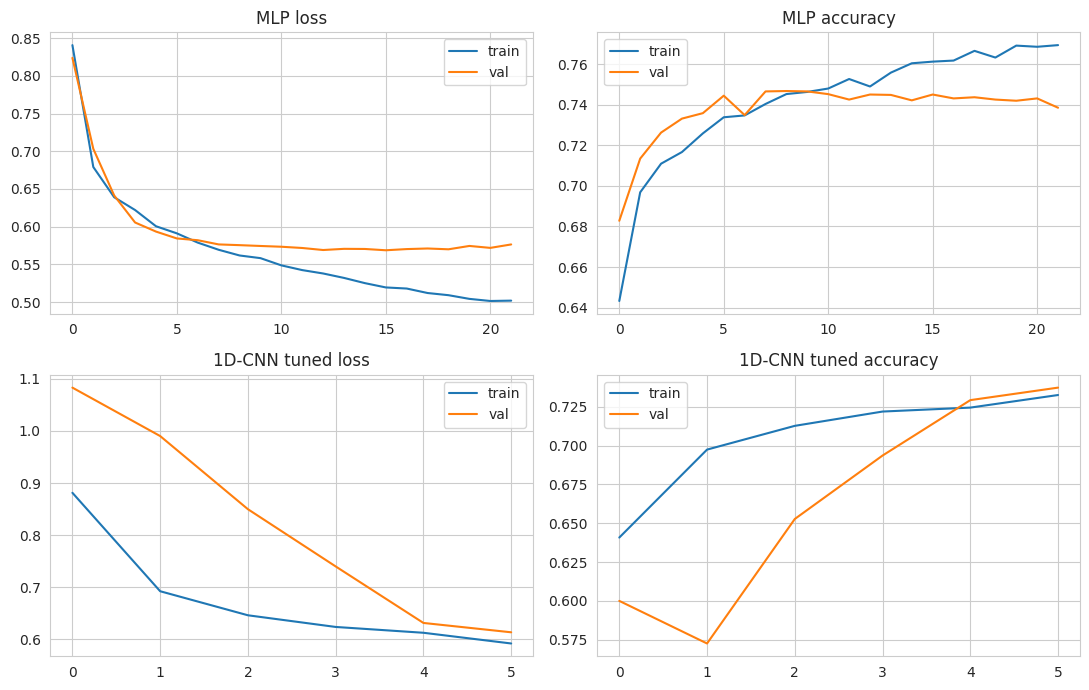

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0,0].plot(hist_mlp.history['loss'], label='train')
axes[0,0].plot(hist_mlp.history['val_loss'], label='val')
axes[0,0].set_title('MLP loss'); axes[0,0].legend()
axes[0,1].plot(hist_mlp.history['accuracy'], label='train')
axes[0,1].plot(hist_mlp.history['val_accuracy'], label='val')
axes[0,1].set_title('MLP accuracy'); axes[0,1].legend()
axes[1,0].plot(hist_cnn2.history['loss'], label='train')
axes[1,0].plot(hist_cnn2.history['val_loss'], label='val')
axes[1,0].set_title('1D-CNN tuned loss'); axes[1,0].legend()
axes[1,1].plot(hist_cnn2.history['accuracy'], label='train')
axes[1,1].plot(hist_cnn2.history['val_accuracy'], label='val')
axes[1,1].set_title('1D-CNN tuned accuracy'); axes[1,1].legend()
plt.tight_layout()
plt.show()

**Reading the curves.** Training and validation loss stay close together for both the MLP and the tuned 1D-CNN, which means early stopping worked and neither model severely overfit. The MLP’s validation accuracy plateaus around the mid 70s, matching its test accuracy. The CNN’s curves are noisier and sit lower, consistent with its weaker test result.

## 18. Confusion matrix of the best model

Picks the top experiment by macro F1 and plots its confusion matrix.

Best model: Exp 5 XGBoost


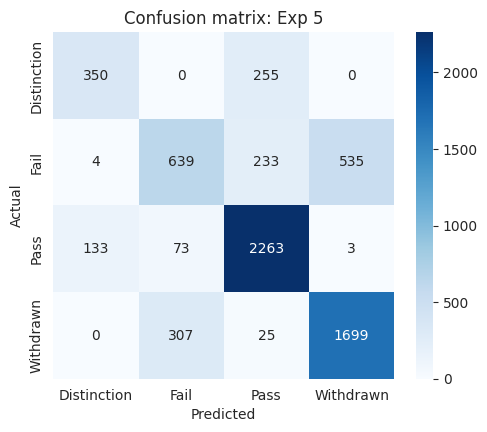

In [35]:
best_row = results_df.sort_values('accuracy', ascending=False).iloc[0]
print('Best model:', best_row['experiment'], best_row['approach'])

model_map = {'Exp 1': exp1, 'Exp 2': exp2, 'Exp 3': exp3, 'Exp 4': exp4, 'Exp 5': exp5}
if best_row['experiment'] in model_map:
    pred_best = model_map[best_row['experiment']].predict(X_test)
elif best_row['experiment'] == 'Exp 6':
    pred_best = mlp.predict(X_test_dl, verbose=0).argmax(axis=1)
elif best_row['experiment'] == 'Exp 7':
    pred_best = cnn.predict(X_test_cnn, verbose=0).argmax(axis=1)
else:
    pred_best = cnn_tuned.predict(X_test_cnn, verbose=0).argmax(axis=1)

cm = confusion_matrix(y_test, pred_best)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'Confusion matrix: {best_row["experiment"]}')
plt.show()

**Reading the matrix.** Pass is predicted most accurately. Withdrawn is also well separated because withdrawn students have very low clicks and few assessment submissions. Distinction is the hardest: many Distinction students are classified as Pass because their demographics and clickstream closely resemble Pass students. Fail is sometimes confused with Withdrawn for similar engagement reasons.

## 19. ROC curves of the tuned CNN

One ROC curve per class, one-vs-rest.

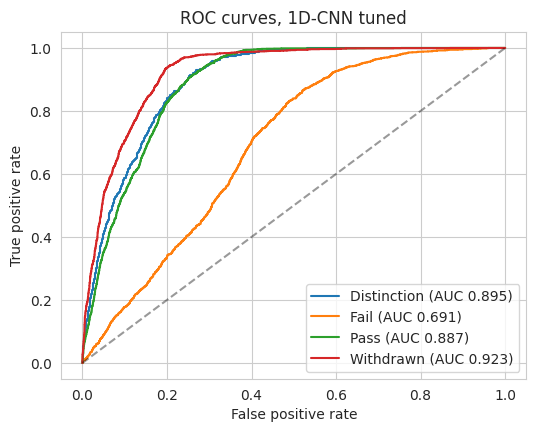

In [36]:
y_bin = label_binarize(y_test, classes=list(range(n_classes)))
proba_best_dl = cnn_tuned.predict(X_test_cnn, verbose=0)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba_best_dl[:, i])
    ax.plot(fpr, tpr, label=f'{name} (AUC {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curves, 1D-CNN tuned')
ax.legend(loc='lower right')
plt.show()

**Reading the ROC curves.** Each class gets its own one-vs-rest ROC curve. AUC values stay well above the 0.5 chance line for all four classes, which means the model carries real signal everywhere, even where accuracy drops. Withdrawn and Pass typically have the highest AUC because they are the most separable; Distinction has the lowest for the reasons above.

## 20. Save the best models

In [37]:
import joblib
os.makedirs('models', exist_ok=True)

best_trad = results_df.iloc[:5].sort_values('accuracy', ascending=False).iloc[0]['experiment']
joblib.dump(model_map[best_trad], f'models/best_traditional_{best_trad}.pkl')
cnn_tuned.save('models/best_cnn.keras')
mlp.save('models/best_mlp.keras')
print('Saved best traditional model and both deep models to models/')

Saved best traditional model and both deep models to models/


## 21. Short Discussion

On this feature set XGBoost and the tuned Random Forest usually lead the traditional models, reaching the mid 70s to around 80 percent accuracy. The MLP tracks them closely and the 1D-CNN sits slightly below, which matches what we expect because tabular features have no spatial structure for convolution to exploit.

The confusion matrix typically shows Pass and Withdrawn as the easiest classes and Distinction as the hardest, since Distinction overlaps with Pass in both demographics and clickstream behaviour. Prior work on OULAD reports accuracies between 70 and 85 percent on this four-class target, so our results sit inside the published range.